**Fixed-tissue longitudinal analysis, 2026-11-09 (v3).**

Every session is measured in the same voxels: masks in each subject's first-session space. Longitudinal only: reads the imaging data and `sub_info.csv`, writes only `outputs_longitudinal/parcel/`. Kernel: brainiak_env. Restart & Run All.

Fixed choices (change in the setup cell):
- **Contrasts**, for capture and voxel selection: the extraction's own (`2_extraction/01_univariate.py` CONTRASTS): face cope 1, house cope 2, object cope 3, word −cope 13. **Patterns**: the single-condition copes 15–18 (design.con: Face_raw, House_raw, Object_raw, Word_raw).
- **Masks** (`MASK_CHOICE`): the group parcels in `derivatives/rois` (MNI ROIs brought to native space by `04_register_mirror.py`) for FFA, PPA and LO; the fusiform search mask for VWFA (no word parcel exists). Section 2a compares parcel and search mask for each ROI on these contrasts.
- **Subjects**: sub-010 excluded permanently (C.S., 2026-11-09). Every result is given with and without sub-108.

1. Inventory. 2a. Mask comparison. 2b. Mask check (numbers). 2c. Mask check (pictures). 3. Pattern change. 4. Patients against controls. 5. Figures and files.

In [14]:
# ── Setup ───────────────────────────────────────────────────────────────────
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import t as tdist
from pathlib import Path
warnings.filterwarnings('ignore')

GIT  = Path('/user_data/csimmon2/git_repos/sym_pt/pipeline')
sys.path.insert(0, str(GIT))
from params import processed_dir
PROC    = Path(processed_dir)
LONG    = GIT/'outputs_longitudinal'
OUTDIR  = LONG/'parcel'; OUTDIR.mkdir(parents=True, exist_ok=True)
SUBINFO = GIT/'sub_info.csv'

EXCL_BASE = ['sub-017','sub-091','sub-095','sub-096','sub-027','sub-084',   # as the longitudinal notebook
             'sub-010']                                                       # excluded permanently, 2026-11-09
VARIANTS    = {'without 108': ['sub-108'], 'with 108': []}
EXCLUDE_SES = []                       # (subject, session) pairs to leave out

ROIS  = ['VWFA','FFA','PPA','LO']      # word, face | house, object
OWN   = {'VWFA':'word','FFA':'face','PPA':'house','LO':'object'}
ASYM  = ['VWFA','FFA']; SYM = ['PPA','LO']
CATS  = ['word','face','house','object']
SEARCHMASK = {'VWFA':'word_VWFA','FFA':'face_FFA','PPA':'house_PPA_strict','LO':'object_LOC'}
PARCEL     = {'FFA':'FFA','PPA':'PPA','LO':'LO'}             # derivatives/rois/<h><name>.nii.gz
MASK_CHOICE = {'VWFA':'searchmask','FFA':'parcel','PPA':'parcel','LO':'parcel'}
# capture and selection: the extraction's contrasts, (cope, negate)  [01_univariate.py CONTRASTS]
SEL = {'face':(1, False), 'house':(2, False), 'object':(3, False), 'word':(13, True)}
# patterns: single-condition copes (design.con 15-18)
CAT_COPE = {'face':15, 'house':16, 'object':17, 'word':18}
Z_THR   = 2.326   # description only (share of mask above it, pictures); the extraction's selective-voxel threshold
SEL_PCT = 20      # top 20% of each mask's voxels for its own contrast, chosen per subject (Nordt et al. 2021)
MIN_VOX = 30
GC = {'control':'#7A7A7A','LH-intact':'#378ADD','RH-intact':'#D85A30'}
N_PERM = 10000
print('processed_dir:', PROC, '| writing to:', OUTDIR)
print('masks:', MASK_CHOICE)

processed_dir: /user_data/csimmon2/sym_pt | writing to: /user_data/csimmon2/git_repos/sym_pt/pipeline/outputs_longitudinal/parcel
masks: {'VWFA': 'searchmask', 'FFA': 'parcel', 'PPA': 'parcel', 'LO': 'parcel'}


In [15]:
# ── 1. Subjects, file rules, inventory ──────────────────────────────────────
# Maps: the files 2_extraction/01_univariate.py reads (the first session's own zstat1 /
# cope1; a later session's *_ses<first> copy, in first-session space), except that a
# session with HighLevel.gfeat.longitudinal is read from that folder's real files, as
# longitudinal/extract.py does. First and last session per subject, as in the
# longitudinal notebook (pre-surgery sessions included).
si = pd.read_csv(SUBINFO)
si['subject_id'] = si['sub'].astype(str)
si['ses_num'] = pd.to_numeric(si['ses'].astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
si = si[~si.subject_id.isin(EXCL_BASE)].dropna(subset=['ses_num'])
for s_, x_ in EXCLUDE_SES: si = si[~((si.subject_id == s_) & (si.ses_num == x_))]

def grp_of(r):
    g = str(r['group']).strip().lower()
    if g == 'control': return 'control'
    if g == 'otc': return 'LH-intact' if str(r['intact_hemi']).strip().lower() == 'left' else 'RH-intact'
    return None                                    # nonOTC and others: not part of this analysis

SUBJ = {}
for s_, g_ in si.groupby('subject_id'):
    g_ = g_.drop_duplicates('ses_num').sort_values('ses_num'); r0 = g_.iloc[0]; gl = grp_of(r0)
    if gl is None or len(g_) < 2: continue
    c_ = str(r0['code']).strip() if pd.notna(r0['code']) else ''
    SUBJ[s_] = dict(grp=gl, code=c_ if c_ else s_.replace('sub-',''),
                    hemis=['l','r'] if gl == 'control' else (['l'] if gl == 'LH-intact' else ['r']),
                    first=int(g_.ses_num.iloc[0]), last=int(g_.ses_num.iloc[-1]), n_ses=len(g_),
                    age_first=float(g_.age.iloc[0]), age_last=float(g_.age.iloc[-1]))
    SUBJ[s_]['interval'] = SUBJ[s_]['age_last'] - SUBJ[s_]['age_first']

def sdir(sid, ses): return PROC/sid/('ses-%02d' % int(ses))
def stat_file(sid, ses, first, cope, kind):         # kind: 'zstat' or 'cope'
    loc = sdir(sid, ses)/'derivatives'/'fsl'/'loc'
    if (loc/'HighLevel.gfeat.longitudinal').exists():
        return loc/'HighLevel.gfeat.longitudinal'/('cope%d.feat' % cope)/'stats'/('%s1.nii.gz' % kind)
    name = ('%s1.nii.gz' % kind) if int(ses) == int(first) else ('%s1_ses%02d.nii.gz' % (kind, int(first)))
    return loc/'HighLevel.gfeat'/('cope%d.feat' % cope)/'stats'/name
def source_file(sid, first, hemi, roi, source):
    if source == 'searchmask':
        return sdir(sid, first)/'ROIs'/('%s_%s_searchmask.nii.gz' % (hemi, SEARCHMASK[roi]))
    return sdir(sid, first)/'derivatives'/'rois'/('%s%s.nii.gz' % (hemi, PARCEL[roi]))
def mask_file(sid, first, hemi, roi): return source_file(sid, first, hemi, roi, MASK_CHOICE[roi])

_cache = {}
def load(p):                                        # cleared per subject to keep memory low
    p = str(p)
    if p not in _cache:
        img = nib.load(p); _cache[p] = np.asarray(img.dataobj, dtype=np.float32)
    return _cache[p]
def brain(sid, first):
    p = sdir(sid, first)/'anat'/'T1w_brain_mask.nii.gz'
    return (load(p) > 0) if p.exists() else None
def sel_z(sid, ses, first, cat):                    # the extraction's contrast for this category, as z
    cope, neg = SEL[cat]; p = stat_file(sid, ses, first, cope, 'zstat')
    if not p.exists(): return None
    z = load(p); return -z if neg else z
def pattern_r(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < MIN_VOX or a[ok].std() == 0 or b[ok].std() == 0: return np.nan, int(ok.sum())
    return float(np.corrcoef(a[ok], b[ok])[0, 1]), int(ok.sum())

inv = []
for s_, inf in SUBJ.items():
    _cache.clear()
    for h in inf['hemis']:
        for roi in ROIS:
            mf = mask_file(s_, inf['first'], h, roi); c = OWN[roi]
            need = [stat_file(s_, x, inf['first'], SEL[c][0], 'zstat') for x in (inf['first'], inf['last'])] + \
                   [stat_file(s_, x, inf['first'], CAT_COPE[q], 'cope') for x in (inf['first'], inf['last']) for q in CATS]
            inv.append(dict(subject_id=s_, code=inf['code'], grp=inf['grp'], hemi=h, roi=roi,
                            mask=MASK_CHOICE[roi], first=inf['first'], last=inf['last'], n_sessions=inf['n_ses'],
                            interval=round(inf['interval'], 2),
                            mask_voxels=int((load(mf) > 0).sum()) if mf.exists() else 0,
                            maps_missing=int(sum(not p.exists() for p in need)),
                            longitudinal_folder=(sdir(s_, inf['last'])/'derivatives'/'fsl'/'loc'/
                                                 'HighLevel.gfeat.longitudinal').exists()))
INV = pd.DataFrame(inv); _cache.clear()
print('subjects with 2+ sessions:', {g: sum(v['grp'] == g for v in SUBJ.values()) for g in GC})
bad = INV[(INV.mask_voxels == 0) | (INV.maps_missing > 0)]
print('rows with a missing mask or map:', len(bad))
if len(bad): print(bad.to_string(index=False))
print(INV.drop_duplicates('subject_id')[['subject_id','code','grp','first','last','n_sessions','interval',
                                         'longitudinal_folder']].to_string(index=False))

subjects with 2+ sessions: {'control': 8, 'LH-intact': 5, 'RH-intact': 3}
rows with a missing mask or map: 0
subject_id code       grp  first  last  n_sessions  interval  longitudinal_folder
   sub-004   UD LH-intact      1     6           5      5.27                False
   sub-008  008 LH-intact      1     2           2      3.12                 True
   sub-018  C15   control      2     3           2      2.50                False
   sub-021   TC RH-intact      1     3           3      2.50                False
   sub-022  C11   control      1     2           2      3.50                False
   sub-025   C5   control      1     3           3      3.27                False
   sub-052  C32   control      1     2           2      1.60                False
   sub-058  C34   control      1     2           2      1.30                False
   sub-062  C20   control      1     2           2      1.00                False
   sub-064  C12   control      1     2           2      1.00           

In [16]:
# ── 2a. Mask comparison, on the extraction's contrasts ──────────────────────
# For each ROI with a parcel: search mask against parcel. Choose on capture (mean z and %
# of the mask above z 2.326 for the ROI's own contrast, first session), not on stability;
# stability (own-category pattern, copes 15-18, whole mask and top 20%) is shown alongside.
# VWFA has only the search mask. MASK_CHOICE in the setup cell sets what is used below.
rows = []
for s_, inf in SUBJ.items():
    _cache.clear(); f, l = inf['first'], inf['last']; bm = brain(s_, f)
    for h in inf['hemis']:
        for roi in ROIS:
            c = OWN[roi]; z = sel_z(s_, f, f, c)
            fa, fb = stat_file(s_, f, f, CAT_COPE[c], 'cope'), stat_file(s_, l, f, CAT_COPE[c], 'cope')
            if z is None or not (fa.exists() and fb.exists()): continue
            A, B = load(fa), load(fb)
            for src in (['searchmask', 'parcel'] if roi in PARCEL else ['searchmask']):
                base = dict(subject_id=s_, code=inf['code'], grp=inf['grp'], hemi=h, roi=roi, mask=src)
                mf = source_file(s_, f, h, roi, src)
                if not mf.exists(): rows.append(dict(base, note='missing')); continue
                m = load(mf) > 0
                if m.shape != z.shape: rows.append(dict(base, note='grid differs')); continue
                if bm is not None and bm.shape == m.shape: m = m & bm
                if m.sum() < MIN_VOX: rows.append(dict(base, note='too small')); continue
                zm = z[m]; top = m & (z >= np.percentile(zm, 100 - SEL_PCT))
                r_all, _ = pattern_r(A[m], B[m]); r_top, _ = pattern_r(A[top], B[top])
                rows.append(dict(base, n_vox=int(m.sum()), mean_z=float(zm.mean()),
                                 pct_active=float(np.mean(zm > Z_THR) * 100), r_all=r_all, r_top20=r_top, note=''))
CMP = pd.DataFrame(rows); _cache.clear()
ok = CMP[CMP.note == '']
pd.set_option('display.width', 220)
print('controls, median (capture first; stability alongside):')
print(ok[ok.grp == 'control'].groupby(['roi', 'mask', 'hemi'])[['n_vox', 'mean_z', 'pct_active', 'r_all', 'r_top20']]
        .median().round(2).to_string())
miss = CMP[CMP.note != '']
if len(miss): print('\nnot computed:'); print(miss.groupby(['roi', 'mask', 'note']).size().to_string())

controls, median (capture first; stability alongside):
                        n_vox  mean_z  pct_active  r_all  r_top20
roi  mask       hemi                                             
FFA  parcel     l      1279.5   -2.12        5.12   0.82     0.86
                r      4173.5    0.13       19.54   0.93     0.90
     searchmask l     10000.5   -2.22        9.08   0.91     0.95
                r      9857.5   -1.19        8.43   0.91     0.95
LO   parcel     l      7068.0    2.85       58.48   0.86     0.89
                r      9369.5    2.53       52.79   0.83     0.91
     searchmask l     39509.5    2.21       43.13   0.90     0.91
                r     39704.5    2.05       42.51   0.89     0.93
PPA  parcel     l      5991.0    1.42       30.20   0.91     0.89
                r      5393.0    1.51       36.36   0.88     0.90
     searchmask l      6023.5   -0.10        6.87   0.60     0.66
                r      6093.0    0.27       10.23   0.61     0.57
VWFA searchmask l    

In [17]:
# ── 2b. Mask check, numbers (the masks in MASK_CHOICE) ───────────────────────
# Every subject, intact hemisphere (both for controls), ROI and session, for the ROI's own
# contrast, in the same voxels in both sessions:
#   mean_z      mean z over the whole mask (no threshold)
#   peak_z      maximum z in the mask
#   pct_active  share of the mask above z = 2.326. Threshold-dependent: lower wherever
#               activation is weaker, so read it as a description, not a group comparison.
mc, grid_bad = [], []
for s_, inf in SUBJ.items():
    _cache.clear(); bm = brain(s_, inf['first'])
    for h in inf['hemis']:
        for roi in ROIS:
            mf = mask_file(s_, inf['first'], h, roi)
            if not mf.exists(): continue
            m = load(mf) > 0
            if bm is not None and bm.shape == m.shape: m = m & bm
            for which, ses in (('first', inf['first']), ('last', inf['last'])):
                z = sel_z(s_, ses, inf['first'], OWN[roi])
                if z is None: continue
                if z.shape != m.shape: grid_bad.append((s_, ses, roi, z.shape, m.shape)); continue
                zm = z[m]
                mc.append(dict(subject_id=s_, code=inf['code'], grp=inf['grp'], hemi=h, roi=roi,
                               session=which, ses=ses, mask_voxels=int(m.sum()),
                               mean_z=float(zm.mean()), peak_z=float(zm.max()),
                               pct_active=float(np.mean(zm > Z_THR) * 100)))
MC = pd.DataFrame(mc); _cache.clear()
if grid_bad: print('MAP AND MASK GRIDS DIFFER (left out):', grid_bad)
for col, lab in [('mean_z', 'median of the mean z inside the mask (no threshold)'),
                 ('pct_active', 'median %% of the mask above z = %.3f (threshold-dependent)' % Z_THR)]:
    print(lab, "for the ROI's own contrast")
    print(MC.pivot_table(index=['grp','hemi','session'], columns='roi', values=col, aggfunc='median')
            .reindex(columns=ROIS).round(2).to_string()); print()
print('patients, each ROI, first -> last session')
P_ = MC[MC.grp != 'control']
print(P_.pivot_table(index=['code','grp','roi'], columns='session', values=['mean_z','peak_z','pct_active'])
        .round(1).to_string())

median of the mean z inside the mask (no threshold) for the ROI's own contrast
roi                     VWFA   FFA   PPA    LO
grp       hemi session                        
LH-intact l    first   -0.43  0.22  0.91  2.46
               last     0.50 -0.05  0.75  2.26
RH-intact r    first   -0.40  0.26  1.03  2.99
               last     1.13  0.20  0.58  3.45
control   l    first    0.38 -2.12  1.42  2.85
               last     0.40 -2.18  2.15  1.90
          r    first    0.10  0.13  1.51  2.53
               last    -0.28  0.55  2.72  1.52

median % of the mask above z = 2.326 (threshold-dependent) for the ROI's own contrast
roi                      VWFA    FFA    PPA     LO
grp       hemi session                            
LH-intact l    first     1.20  10.58  12.28  46.24
               last      8.88  10.42  32.45  41.66
RH-intact r    first     8.13  21.44  29.36  56.92
               last     22.45   8.44  13.14  62.58
control   l    first    11.21   5.12  30.20  58.48
       

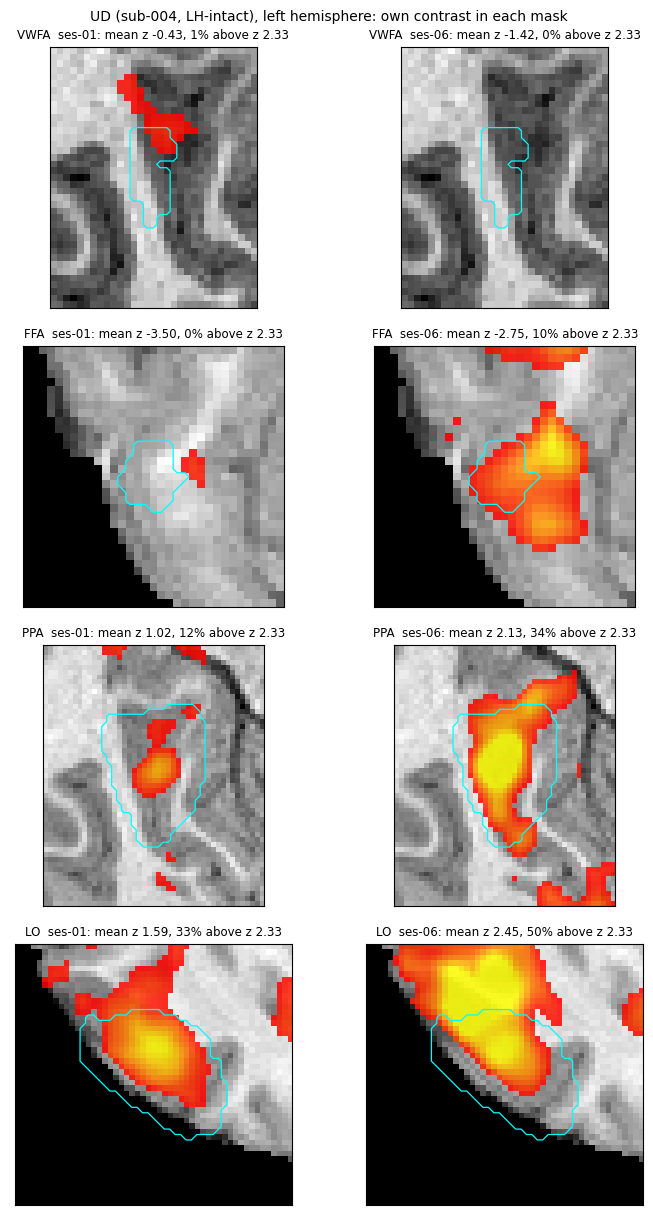

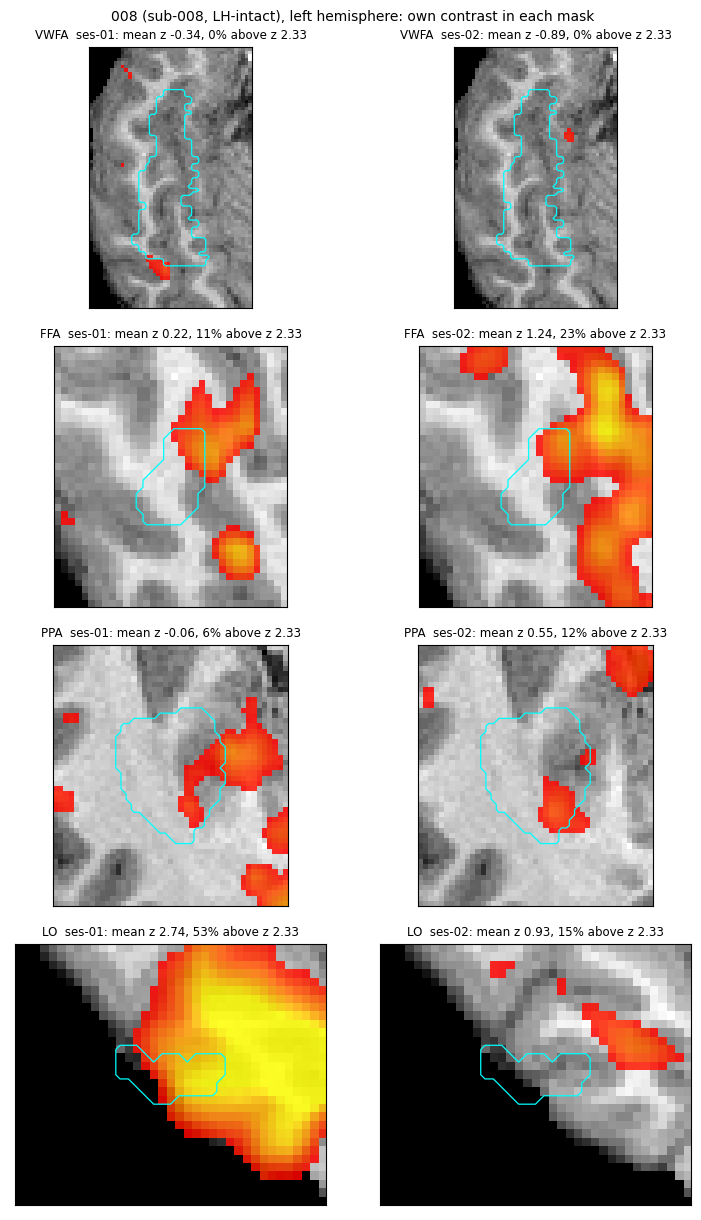

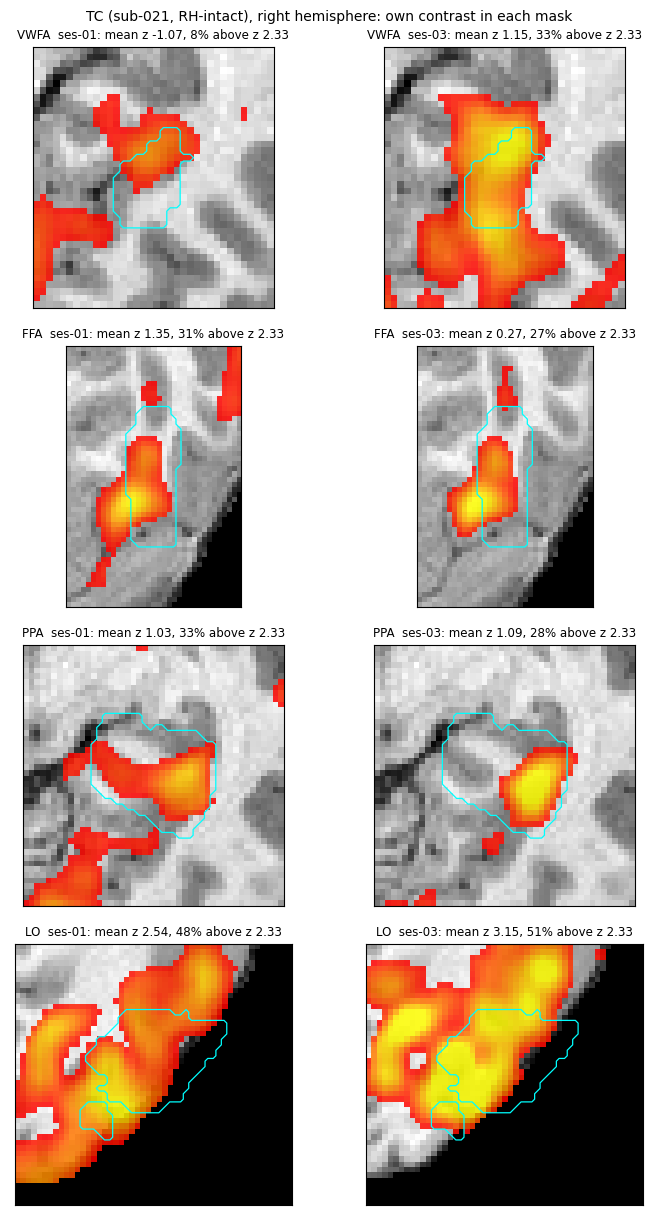

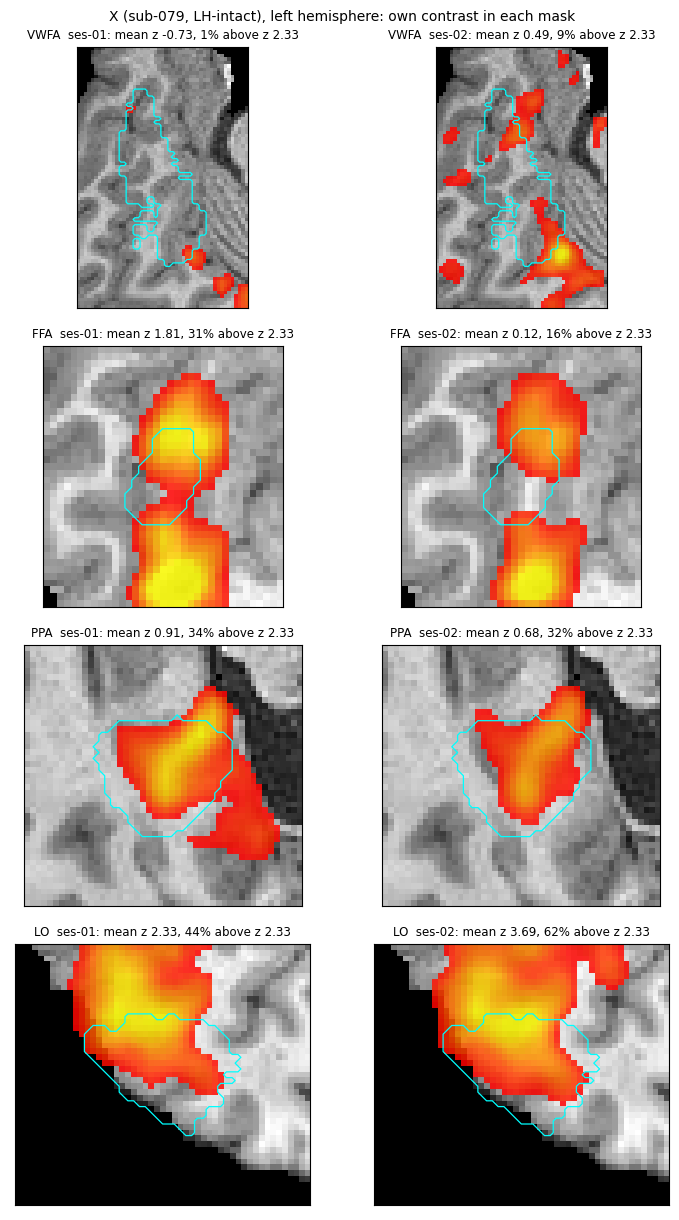

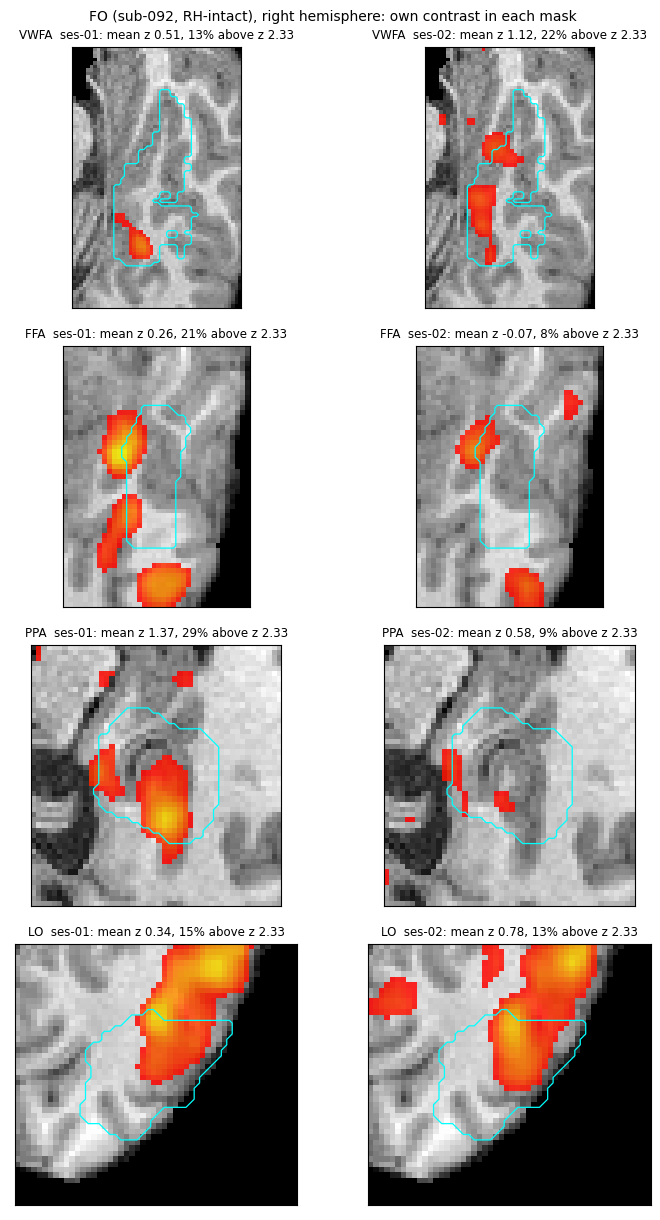

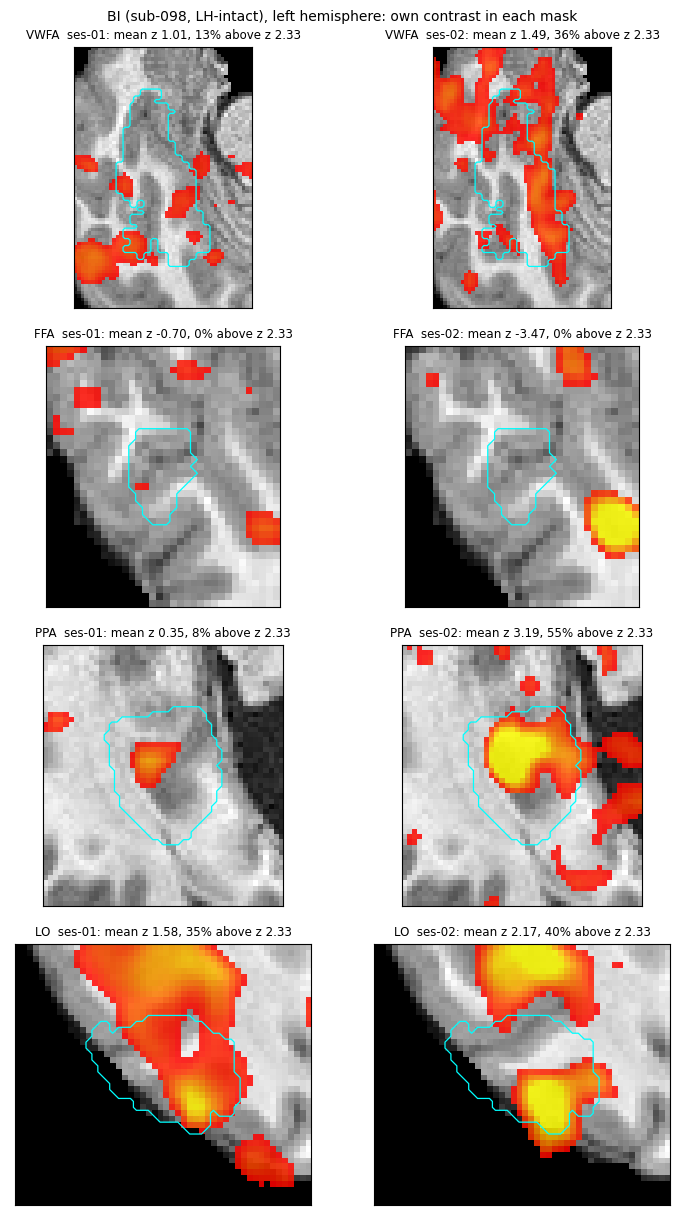

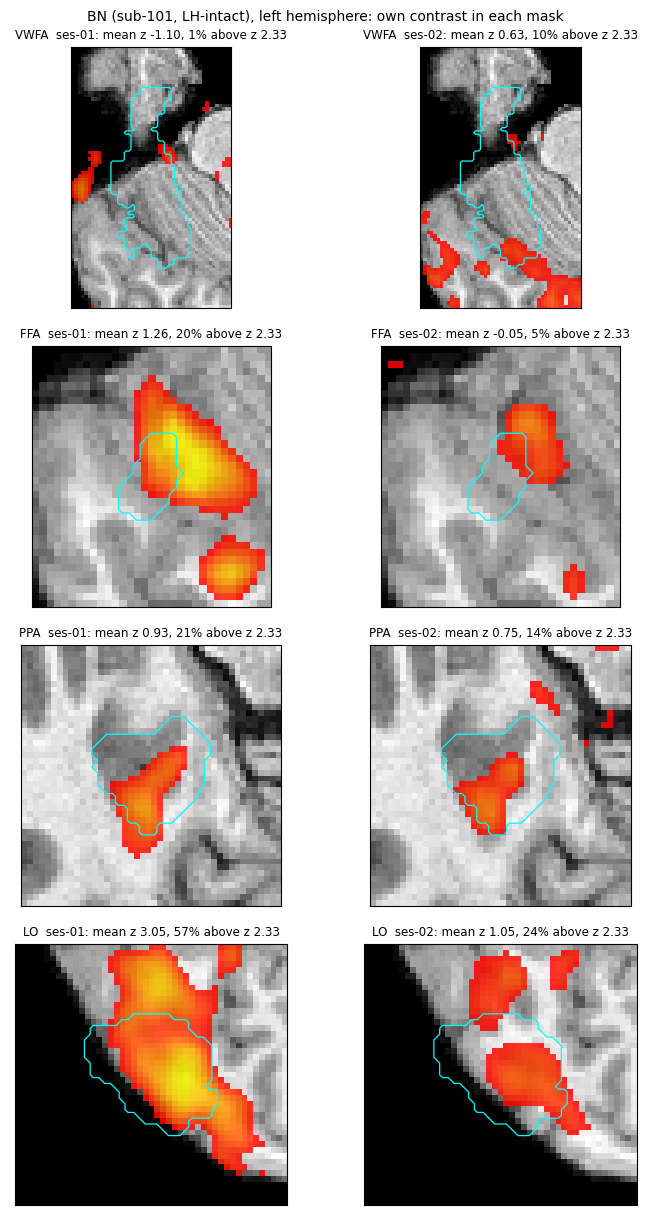

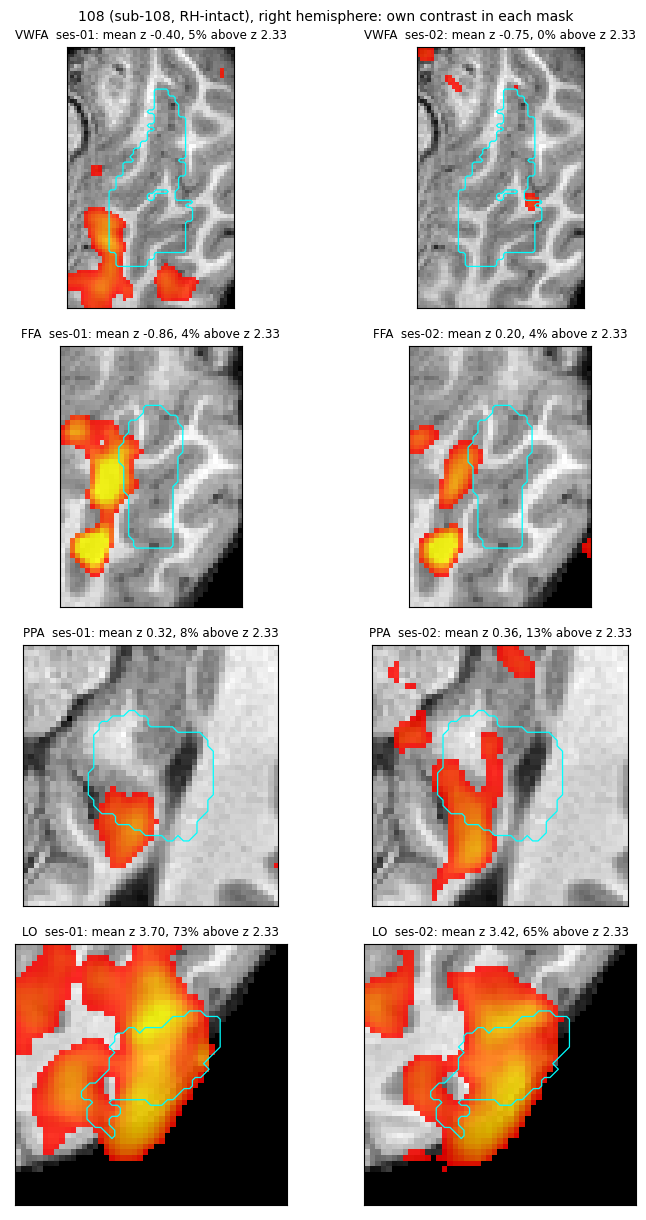

In [18]:
# ── 2c. Mask check, pictures ────────────────────────────────────────────────
# Each patient (controls too if SHOW_CONTROLS): one row per ROI, first and last session
# side by side. First-session T1, the ROI's own contrast above z = 2.326 (hot; display
# only), the mask outline (cyan). Axial slice through the first session's peak inside the
# mask, the same slice for both sessions. Voxel orientation (not radiological).
SHOW_CONTROLS = False
def _crop(m2, pad=12):
    ii, jj = np.where(m2)
    if not len(ii): return slice(None), slice(None)
    return slice(max(ii.min() - pad, 0), ii.max() + pad + 1), slice(max(jj.min() - pad, 0), jj.max() + pad + 1)
for s_, inf in SUBJ.items():
    if inf['grp'] == 'control' and not SHOW_CONTROLS: continue
    _cache.clear(); f, l = inf['first'], inf['last']
    t1p = sdir(s_, f)/'anat'/'T1w_brain.nii.gz'
    if not t1p.exists(): print(s_, ': no first-session T1'); continue
    t1 = load(t1p)
    for h in inf['hemis']:
        fig, axes = plt.subplots(len(ROIS), 2, figsize=(7.6, 3.1 * len(ROIS)))
        for i, roi in enumerate(ROIS):
            mf = mask_file(s_, f, h, roi)
            z0, z1 = sel_z(s_, f, f, OWN[roi]), sel_z(s_, l, f, OWN[roi])
            if not mf.exists() or z0 is None or z1 is None:
                for ax in axes[i]: ax.axis('off')
                axes[i][0].set_title(roi + ': mask or map missing', fontsize=9); continue
            m = load(mf) > 0
            if not (m.shape == z0.shape == z1.shape == t1.shape):
                for ax in axes[i]: ax.axis('off')
                axes[i][0].set_title(roi + ': grids differ', fontsize=9); continue
            k = np.unravel_index(np.argmax(np.where(m, z0, -np.inf)), m.shape)[2]
            ci, cj = _crop(m[:, :, k])
            vmax = max(8.0, float(np.nanmax(z0[m])))
            for j, (zz, ses) in enumerate(((z0, f), (z1, l))):
                ax = axes[i][j]; zs = zz[ci, cj, k]
                ax.imshow(t1[ci, cj, k].T, cmap='gray', origin='lower', interpolation='nearest')
                ax.imshow(np.ma.masked_where(zs <= Z_THR, zs).T, cmap='autumn', origin='lower',
                          vmin=Z_THR, vmax=vmax, alpha=0.85, interpolation='nearest')
                if m[ci, cj, k].any():
                    ax.contour(m[ci, cj, k].T.astype(float), levels=[0.5], colors='cyan', linewidths=0.9)
                pct = float(np.mean(zz[m] > Z_THR) * 100)
                ax.set_title('%s  ses-%02d: mean z %.2f, %.0f%% above z %.2f' %
                             (roi, int(ses), float(zz[m].mean()), pct, Z_THR), fontsize=8.5)
                ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle('%s (%s, %s), %s hemisphere: own contrast in each mask' %
                     (inf['code'], s_, inf['grp'], 'left' if h == 'l' else 'right'), fontsize=10)
        fig.tight_layout(); fig.savefig(OUTDIR/('maskcheck_%s_%s.png' % (s_, h)), dpi=150, bbox_inches='tight')
        plt.show(); plt.close(fig)
_cache.clear()

In [19]:
# ── 3. Pattern change in fixed tissue ───────────────────────────────────────
# For each subject, hemisphere and ROI: the correlation, across the mask's voxels, of each
# category's response pattern (single-condition copes 15-18) at the first and the last
# session. The same voxels in both sessions; lower r = more change. Two voxel sets:
#   'mask'         every voxel of the mask (within the first session's brain mask)
#   'top20_first'  the subject's top SEL_PCT% of mask voxels for the ROI's own contrast at
#                  the FIRST session, then kept fixed: a share, not a z cut-off, so every
#                  subject keeps the same proportion of the mask however strong the activation.
# This is the multivoxel-pattern correlation Nordt et al. (2021) used for run-to-run
# reliability, here between sessions.
rows = []
for s_, inf in SUBJ.items():
    _cache.clear(); f, l = inf['first'], inf['last']; bm = brain(s_, f)
    for h in inf['hemis']:
        for roi in ROIS:
            mf = mask_file(s_, f, h, roi); zs = sel_z(s_, f, f, OWN[roi])
            if not mf.exists() or zs is None: continue
            m = load(mf) > 0
            if bm is not None and bm.shape == m.shape: m = m & bm
            if zs.shape != m.shape or m.sum() < MIN_VOX: continue
            sets = {'mask': m, 'top20_first': m & (zs >= np.percentile(zs[m], 100 - SEL_PCT))}
            for c in CATS:
                fa, fb = stat_file(s_, f, f, CAT_COPE[c], 'cope'), stat_file(s_, l, f, CAT_COPE[c], 'cope')
                if not (fa.exists() and fb.exists()): continue
                A, B = load(fa), load(fb)
                if A.shape != m.shape or B.shape != m.shape: continue
                for vs, vox in sets.items():
                    r, n = pattern_r(A[vox], B[vox])
                    rows.append(dict(subject_id=s_, code=inf['code'], grp=inf['grp'], hemi=h, roi=roi,
                                     category=c, own=(c == OWN[roi]), voxels=vs, n_vox=n, r=r,
                                     z=float(np.arctanh(np.clip(r, -0.999, 0.999))) if np.isfinite(r) else np.nan,
                                     first=f, last=l, interval=inf['interval'], age_last=inf['age_last']))
PAT = pd.DataFrame(rows); _cache.clear()
own_ = PAT[PAT.own]
print('own-category pattern stability (r, first vs last session), median:')
print(own_.pivot_table(index=['voxels','grp','hemi'], columns='roi', values='r', aggfunc='median')
          .reindex(columns=ROIS).round(2).to_string())
print('\npatients:')
print(own_[own_.grp != 'control'].pivot_table(index=['voxels','code','grp'], columns='roi', values='r')
          .reindex(columns=ROIS).round(2).to_string())

own-category pattern stability (r, first vs last session), median:
roi                         VWFA   FFA   PPA    LO
voxels      grp       hemi                        
mask        LH-intact l     0.51  0.60  0.85  0.89
            RH-intact r     0.80  0.76  0.84  0.89
            control   l     0.83  0.82  0.91  0.86
                      r     0.78  0.93  0.88  0.83
top20_first LH-intact l     0.46  0.71  0.77  0.76
            RH-intact r     0.73  0.73  0.88  0.88
            control   l     0.79  0.86  0.89  0.89
                      r     0.77  0.90  0.90  0.91

patients:
roi                         VWFA   FFA   PPA    LO
voxels      code grp                              
mask        008  LH-intact -0.16  0.73  0.85  0.76
            108  RH-intact  0.79  0.63  0.51  0.82
            BI   LH-intact  0.81  0.39  0.73  0.90
            BN   LH-intact  0.51  0.60  0.92  0.89
            FO   RH-intact  0.80  0.76  0.84  0.89
            TC   RH-intact  0.92  0.94  0.97  0.93
    

In [20]:
# ── 4. Patients against controls ────────────────────────────────────────────
# Per subject and hemisphere: gap = mean Fisher-z own-category stability at PPA and LO
# minus at VWFA and FFA (all four needed). Then, for both variants and both voxel sets:
#   gap within each group (sign-flip permutation);
#   each patient group against matched-hemisphere controls: difference in mean gap
#     (label permutation), and each patient's Crawford-Howell t against those controls;
#   the cross-sectional grid's 1-df tests on the four own-category values: interaction()
#     below is copied verbatim from 4_analyses/04_marlene_grid.py, with its codes.
def interaction(df, modifier, n_perm, seed=0, paired=False):
    """OLS: val ~ subject dummies + category dummies + grp*modifier.

    Subject dummies absorb every subject-level effect (overall signal level,
    age, sex, scanner) so the interaction is estimated purely within subject.

    Between-subject comparisons: permutation shuffles the group label across
    subjects, keeping each subject's four values together.

    Paired comparisons: every subject appears in BOTH groups, so shuffling
    across subjects would break the pairing. Instead each subject's two group
    labels are flipped together with probability 0.5, which is the correct
    exchangeability for a within-subject contrast.
    """
    df = df.copy()
    key = 'pair' if 'pair' in df.columns else 'roi'
    df['m'] = df[key].map(modifier).astype(float)
    if df['grp'].nunique() < 2 or df['m'].nunique() < 2:
        return np.nan, np.nan, 0, 0

    S = pd.get_dummies(df['subject_id']).astype(float).values
    C = pd.get_dummies(df['roi'], drop_first=True).astype(float).values
    if key == 'pair':
        C = np.hstack([C, pd.get_dummies(df['pair'],
                                         drop_first=True).astype(float).values])
    y = df['val'].to_numpy(float)
    mvec = df['m'].to_numpy(float)

    def beta(grp_vec):
        X = np.hstack([S, C, (grp_vec * mvec)[:, None]])
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        return b[-1]

    g_obs = df['grp'].to_numpy(float)
    obs = beta(g_obs)
    rng = np.random.default_rng(seed)
    sid = df['subject_id']
    k = 0

    if paired:
        ids = sid.unique()
        for _ in range(n_perm):
            flip = dict(zip(ids, rng.integers(0, 2, len(ids)).astype(float)))
            g = np.abs(g_obs - sid.map(flip).to_numpy(float))
            if abs(beta(g)) >= abs(obs) - 1e-12:
                k += 1
        n = int(len(ids))
        return obs, (k + 1) / (n_perm + 1), n, n

    sub = df.drop_duplicates('subject_id').set_index('subject_id')['grp']
    ids, labels = sub.index.to_numpy(), sub.to_numpy(float)
    for _ in range(n_perm):
        m = dict(zip(ids, rng.permutation(labels)))
        if abs(beta(sid.map(m).to_numpy(float))) >= abs(obs) - 1e-12:
            k += 1
    n0 = int((labels == 0).sum())
    n1 = int((labels == 1).sum())
    return obs, (k + 1) / (n_perm + 1), n0, n1

LI233 = {'word':0.389,'face':0.245,'object':0.130,'house':0.124}    # 04_marlene_grid.py
RANK  = {'word':4.0,'face':3.0,'object':1.5,'house':1.5}
BINA  = {'word':1,'face':1,'house':0,'object':0}
SPECS = {'uni/bi':BINA, '|LI| gradient':LI233, 'rank order':RANK}

def crawford(x, ctrl):
    ctrl = np.asarray(ctrl, float); ctrl = ctrl[np.isfinite(ctrl)]; n = len(ctrl)
    if n < 3 or not np.isfinite(x): return np.nan, np.nan
    t_ = (x - ctrl.mean()) / (ctrl.std(ddof=1) * np.sqrt((n + 1.0) / n))
    return float(t_), float(2 * tdist.sf(abs(t_), n - 1))
def perm_flip(d, seed=0):
    d = np.asarray(d, float); d = d[np.isfinite(d)]
    if len(d) < 2: return np.nan
    rng = np.random.RandomState(seed); obs = d.mean()
    null = (rng.choice([-1.0, 1.0], size=(N_PERM, len(d))) * d).mean(1)
    return float((np.sum(np.abs(null) >= abs(obs) - 1e-12) + 1) / (N_PERM + 1))
def perm_diff(a, b, seed=0):
    a = np.asarray(a, float); b = np.asarray(b, float); a = a[np.isfinite(a)]; b = b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2: return np.nan
    rng = np.random.RandomState(seed); obs = b.mean() - a.mean(); pool = np.r_[a, b]; k = 0
    for _ in range(N_PERM):
        q = rng.permutation(pool)
        if abs(q[len(a):].mean() - q[:len(a)].mean()) >= abs(obs) - 1e-12: k += 1
    return float((k + 1) / (N_PERM + 1))
def gaps(o):
    w = o.pivot_table(index=['subject_id','code','grp','hemi'], columns='roi', values='z')
    if not all(r in w.columns for r in ROIS): return pd.DataFrame(columns=['subject_id','code','grp','hemi','gap'])
    w = w.dropna(subset=ROIS); w['gap'] = w[SYM].mean(1) - w[ASYM].mean(1)
    return w.reset_index()

STATS, CRAW = [], []
COMPS = {'LH ctrl vs LH-intact': (('control','l'), ('LH-intact','l')),
         'RH ctrl vs RH-intact': (('control','r'), ('RH-intact','r')),
         'LH ctrl vs RH ctrl':   (('control','l'), ('control','r'))}
for vname, drop in VARIANTS.items():
    for vs in ['mask', 'top20_first']:
        o = PAT[PAT.own & (PAT.voxels == vs) & ~PAT.subject_id.isin(drop)]
        G = gaps(o)
        ctl = {h: G[(G.grp == 'control') & (G.hemi == h)].gap.values for h in 'lr'}
        for gname, h in [('control','l'), ('control','r'), ('LH-intact','l'), ('RH-intact','r')]:
            d = G[(G.grp == gname) & (G.hemi == h)].gap.values
            STATS.append(dict(variant=vname, voxels=vs, test='gap within group', group='%s %s' % (gname, h.upper()),
                              n=str(len(d)), estimate=float(np.mean(d)) if len(d) else np.nan, p=perm_flip(d)))
        for gname, h in [('LH-intact','l'), ('RH-intact','r')]:
            d = G[(G.grp == gname) & (G.hemi == h)]
            STATS.append(dict(variant=vname, voxels=vs, test='gap vs matched controls', group=gname,
                              n='%d vs %d' % (len(ctl[h]), len(d)),
                              estimate=float(d.gap.mean() - np.mean(ctl[h])) if len(d) and len(ctl[h]) else np.nan,
                              p=perm_diff(ctl[h], d.gap.values)))
            for _, r_ in d.iterrows():
                t_, p_ = crawford(r_.gap, ctl[h])
                CRAW.append(dict(variant=vname, voxels=vs, code=r_.code, subject_id=r_.subject_id, grp=gname,
                                 gap=r_.gap, control_mean=float(np.mean(ctl[h])) if len(ctl[h]) else np.nan,
                                 t=t_, p=p_))
        X = o[['subject_id','grp','hemi','roi','z']].rename(columns={'z':'val'}).dropna(subset=['val'])
        for comp, (A_, B_) in COMPS.items():
            a = X[(X.grp == A_[0]) & (X.hemi == A_[1])]; b = X[(X.grp == B_[0]) & (X.hemi == B_[1])]
            df = pd.concat([a.assign(grp=0), b.assign(grp=1)], ignore_index=True)
            paired = (A_[0] == 'control' and B_[0] == 'control')
            u = df.groupby('subject_id').size(); df = df[df.subject_id.isin(u[u == len(ROIS) * (2 if paired else 1)].index)]
            for spec, codes in SPECS.items():
                beta, p, n0, n1 = interaction(df[['subject_id','roi','val','grp']], {r: codes[OWN[r]] for r in ROIS},
                                              n_perm=N_PERM // 2, seed=0, paired=paired)
                STATS.append(dict(variant=vname, voxels=vs, test='grid: ' + spec, group=comp,
                                  n='%d vs %d' % (n0, n1), estimate=beta, p=p))
ST = pd.DataFrame(STATS); CR = pd.DataFrame(CRAW)
pd.set_option('display.width', 220)
for vname in VARIANTS:
    print('\n' + '=' * 30, vname, '=' * 30)
    print(ST[ST.variant == vname].drop(columns='variant').round(3).to_string(index=False))
    print('\neach patient against matched-hemisphere controls (Crawford-Howell):')
    print(CR[CR.variant == vname].drop(columns='variant').round(3).to_string(index=False))


============================== without 108 ==============================
     voxels                    test                group      n  estimate     p
       mask        gap within group            control L      8     0.236 0.275
       mask        gap within group            control R      8     0.097 0.580
       mask        gap within group          LH-intact L      5     0.594 0.061
       mask        gap within group          RH-intact R      2     0.221 0.495
       mask gap vs matched controls            LH-intact 8 vs 5     0.358 0.207
       mask gap vs matched controls            RH-intact 8 vs 2     0.125 0.749
       mask            grid: uni/bi LH ctrl vs LH-intact 8 vs 5    -0.358 0.220
       mask     grid: |LI| gradient LH ctrl vs LH-intact 8 vs 5    -1.877 0.099
       mask        grid: rank order LH ctrl vs LH-intact 8 vs 5    -0.189 0.120
       mask            grid: uni/bi RH ctrl vs RH-intact 8 vs 2    -0.125 0.757
       mask     grid: |LI| gradient RH ctrl v

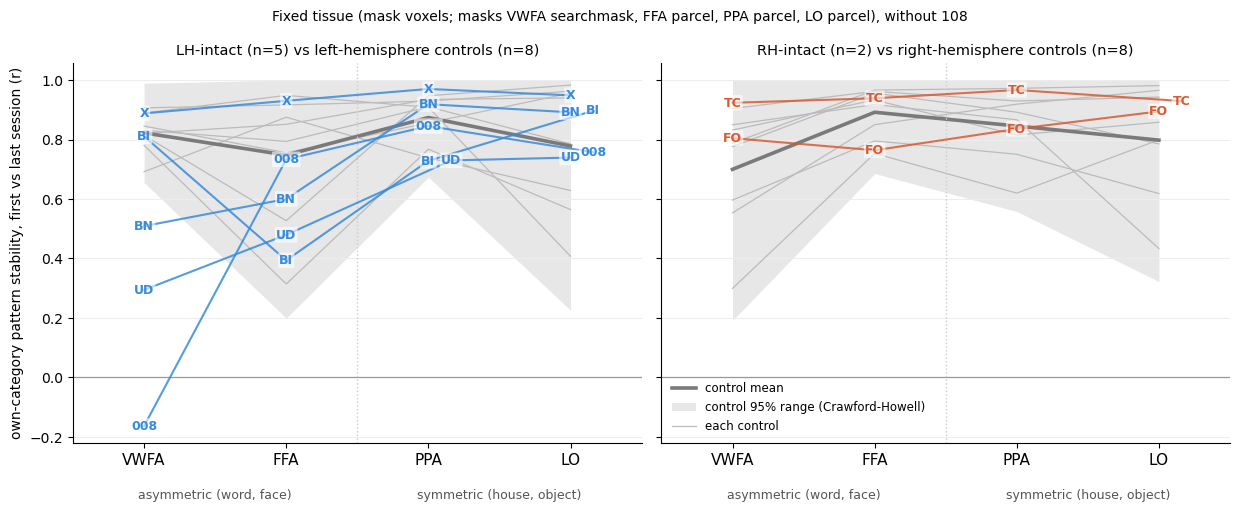

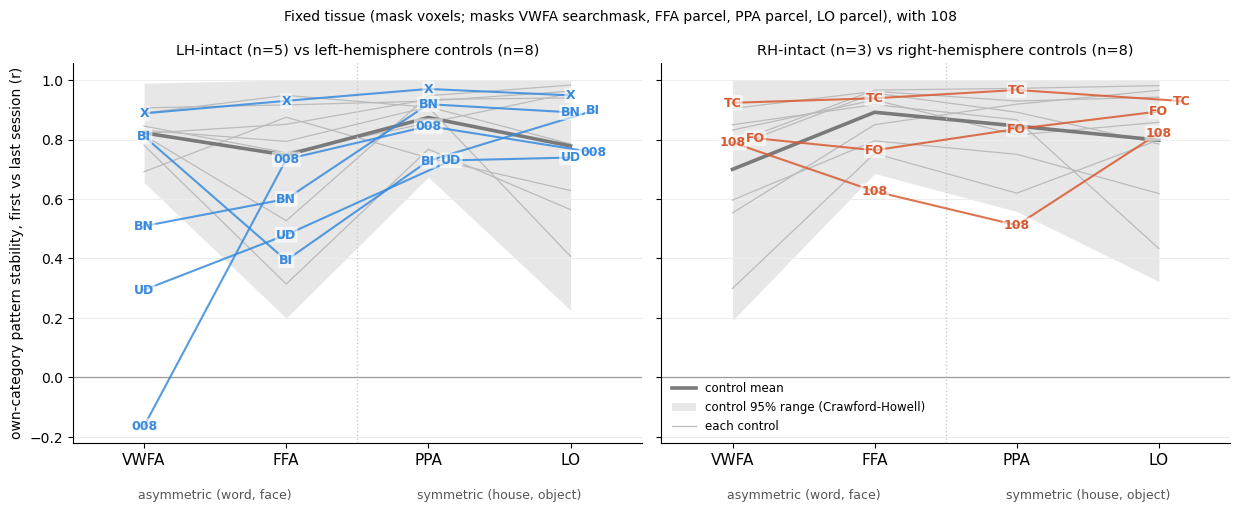

In [21]:
# ── 5a. Figure: own-category stability across the four ROIs ─────────────────
# Left: LH-intact patients with left-hemisphere controls; right: RH-intact with
# right-hemisphere controls. Each patient a line drawn with its code; controls: each control
# as a thin grey line, their mean, and the Crawford-Howell 95% range, mean +/- t(.975, n-1)
# * SD * sqrt((n+1)/n), clipped to [-1, 1]. Values shown as r; the tests above use z.
FIG_VOXELS = 'mask'           # or 'top20_first'
def code_x(ys, xc, gap, step):
    # a code sits at xc unless it would overlap one already placed; y stays exact
    ys = np.asarray(ys, float); x = np.full(len(ys), float(xc)); placed = []
    cand = [0] + [sg * k for k in range(1, len(ys) + 1) for sg in (1, -1)]
    for j in np.argsort(ys):
        if not np.isfinite(ys[j]): continue
        for c_ in cand:
            xx = xc + c_ * step
            if all(abs(ys[j] - ys[q]) >= gap or abs(xx - x[q]) >= 0.999 * step for q in placed):
                x[j] = xx; break
        placed.append(j)
    return x
def draw_codes(ax, xs, ys, texts, color, fs=9):
    for x, y, t_ in zip(xs, ys, texts):
        ax.text(x, y, t_, ha='center', va='center', fontsize=fs, color=color, fontweight='bold', zorder=6,
                bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.6))
    if len(xs): ax.update_datalim(np.column_stack([xs, ys])); ax.autoscale_view()
X4 = np.arange(len(ROIS))
for vname, drop in VARIANTS.items():
    o = PAT[PAT.own & (PAT.voxels == FIG_VOXELS) & ~PAT.subject_id.isin(drop)]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharey=True); fig.patch.set_facecolor('white')
    for ax, h, gname in [(axes[0], 'l', 'LH-intact'), (axes[1], 'r', 'RH-intact')]:
        ax.yaxis.grid(True, color='#ededed', lw=0.8); ax.set_axisbelow(True); ax.axhline(0, color='#999', lw=0.9)
        cw = (o[(o.grp == 'control') & (o.hemi == h)]
              .pivot_table(index='subject_id', columns='roi', values='r').reindex(columns=ROIS))
        for _, row in cw.iterrows(): ax.plot(X4, row.values, '-', color='#bbbbbb', lw=0.9, zorder=1)
        n = cw.notna().sum().values.astype(float); mu = cw.mean().values; sd = cw.std(ddof=1).values
        hw = np.where(n >= 3, tdist.ppf(0.975, np.maximum(n - 1, 1)) * sd * np.sqrt((n + 1) / np.maximum(n, 1)), np.nan)
        ax.fill_between(X4, np.clip(mu - hw, -1, 1), np.clip(mu + hw, -1, 1), color=GC['control'], alpha=0.18, lw=0, zorder=0)
        ax.plot(X4, mu, '-', color=GC['control'], lw=2.6, zorder=2)
        pw = (o[o.grp == gname].pivot_table(index=['subject_id','code'], columns='roi', values='r')
              .reindex(columns=ROIS))
        if len(pw):
            XP = np.vstack([code_x(pw[r].values, i, 0.05, 0.16) for i, r in enumerate(ROIS)]).T
            for k_, ((s_, cd), row) in enumerate(pw.iterrows()):
                y = row.values.astype(float); ok = np.isfinite(y)
                ax.plot(XP[k_][ok], y[ok], '-', color=GC[gname], lw=1.5, alpha=0.85, zorder=3)
                draw_codes(ax, XP[k_][ok], y[ok], [cd] * int(ok.sum()), GC[gname])
        ax.axvline(1.5, color='#ccc', lw=1, ls=':'); ax.set_xlim(-0.5, len(ROIS) - 0.5)
        ax.set_xticks(X4); ax.set_xticklabels(ROIS, fontsize=11)
        tr = ax.get_xaxis_transform()
        ax.text(0.5, -0.12, 'asymmetric (word, face)', transform=tr, ha='center', va='top', fontsize=9, color='#555')
        ax.text(2.5, -0.12, 'symmetric (house, object)', transform=tr, ha='center', va='top', fontsize=9, color='#555')
        ax.set_title('%s (n=%d) vs %s-hemisphere controls (n=%d)' %
                     (gname, len(pw), 'left' if h == 'l' else 'right', int(n.max()) if len(n) else 0), fontsize=10.5)
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    axes[0].set_ylabel('own-category pattern stability, first vs last session (r)', fontsize=10)
    axes[1].legend(handles=[Line2D([0], [0], color=GC['control'], lw=2.6, label='control mean'),
                            Patch(facecolor=GC['control'], alpha=0.18, label='control 95% range (Crawford-Howell)'),
                            Line2D([0], [0], color='#bbbbbb', lw=0.9, label='each control')],
                   frameon=False, fontsize=8.5, loc='best')
    fig.suptitle('Fixed tissue (%s voxels; masks %s), %s' % (FIG_VOXELS,
                 ', '.join('%s %s' % (r, MASK_CHOICE[r]) for r in ROIS), vname), fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTDIR/('stability_%s_%s.png' % (FIG_VOXELS, vname.replace(' ', '_'))), dpi=200, bbox_inches='tight')
    plt.show(); plt.close(fig)

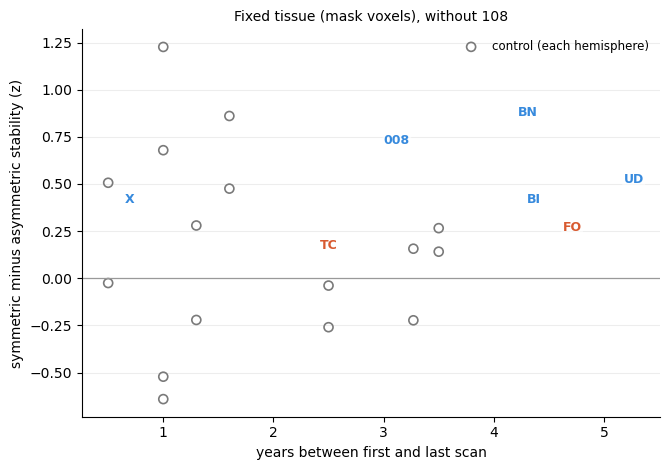

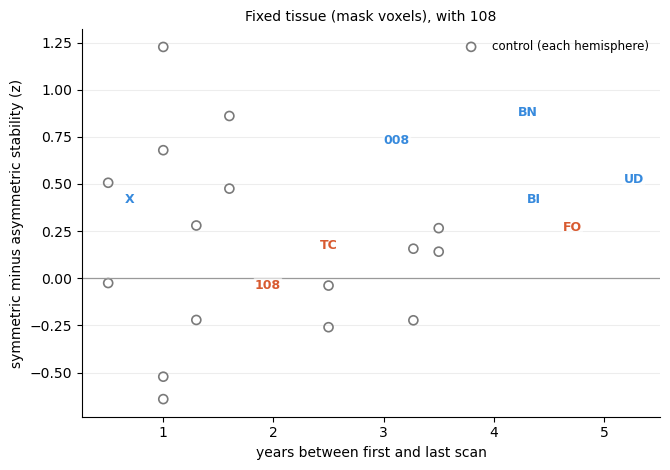

In [22]:
# ── 5b. Figure: the gap against the time between scans ──────────────────────
# One point per subject and hemisphere: symmetric minus asymmetric own-category
# stability (Fisher z), against years between the first and last scan.
for vname, drop in VARIANTS.items():
    G = gaps(PAT[PAT.own & (PAT.voxels == FIG_VOXELS) & ~PAT.subject_id.isin(drop)])
    if not len(G): continue
    G['interval'] = G.subject_id.map(lambda s: SUBJ[s]['interval'])
    fig, ax = plt.subplots(figsize=(6.8, 4.8)); fig.patch.set_facecolor('white')
    ax.axhline(0, color='#999', lw=0.9); ax.yaxis.grid(True, color='#ededed', lw=0.8); ax.set_axisbelow(True)
    c = G[G.grp == 'control']
    ax.scatter(c.interval, c.gap, s=42, facecolors='none', edgecolors=GC['control'], lw=1.2,
               label='control (each hemisphere)')
    for gname in ['LH-intact', 'RH-intact']:
        p_ = G[G.grp == gname]
        draw_codes(ax, p_.interval.values, p_.gap.values, list(p_.code), GC[gname], fs=9)
    ax.set_xlabel('years between first and last scan'); ax.set_ylabel('symmetric minus asymmetric stability (z)')
    ax.legend(frameon=False, fontsize=8.5, loc='best')
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    ax.set_title('Fixed tissue (%s voxels), %s' % (FIG_VOXELS, vname), fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTDIR/('gap_vs_interval_%s_%s.png' % (FIG_VOXELS, vname.replace(' ', '_'))), dpi=200, bbox_inches='tight')
    plt.show(); plt.close(fig)

In [23]:
# ── 5c. Files ───────────────────────────────────────────────────────────────
INV.to_csv(OUTDIR/'inventory.csv', index=False)
CMP.to_csv(OUTDIR/'mask_comparison.csv', index=False)
MC.to_csv(OUTDIR/'mask_check.csv', index=False)
PAT.to_csv(OUTDIR/'pattern_stability.csv', index=False)
ST.to_csv(OUTDIR/'stats.csv', index=False)
CR.to_csv(OUTDIR/'crawford.csv', index=False)
print('written to', OUTDIR, ':', sorted(p.name for p in OUTDIR.glob('*.csv')))

written to /user_data/csimmon2/git_repos/sym_pt/pipeline/outputs_longitudinal/parcel : ['crawford.csv', 'inventory.csv', 'lo_pfs_check.csv', 'mask_candidates.csv', 'mask_check.csv', 'mask_comparison.csv', 'pattern_stability.csv', 'stats.csv']


## End

In [ ]:
# ── Search mask with the pipeline's peak as a red dot ────────────────────────
# For each control (SHOW_CONTROLS) and patient (SHOW_PATIENTS), each intact hemisphere (both
# for controls): one row per ROI; first and last session, each in three planes through the
# pipeline's peak (maximum z of the ROI's contrast inside its search mask, first-session
# brain mask applied, no threshold). First-session T1, search mask shaded blue, peak as a
# red dot. If a stronger maximum sits just outside the mask (within NEAR_MM mm), it is a
# yellow x when within 3 slices of the plane, and the title gives its z and distance.
# The last-session title also gives how far the peak moved from the first session.
# Voxel orientation (not radiological). Read-only; figures go to outputs_longitudinal/parcel.
from scipy.ndimage import binary_dilation
SHOW_CONTROLS = True
SHOW_PATIENTS = False      # patients were drawn already
NEAR_MM = 6
_r = np.arange(-NEAR_MM, NEAR_MM + 1)
BALL = (_r[:, None, None]**2 + _r[None, :, None]**2 + _r[None, None, :]**2) <= NEAR_MM**2
SMASK = {'VWFA': 'word_VWFA', 'FFA': 'face_FFA', 'PPA': 'house_PPA_strict', 'LO': 'object_LOC'}
CONTRAST = {'VWFA': (13, True), 'FFA': (1, False), 'PPA': (2, False), 'LO': (3, False)}   # 01_univariate.py
ROI4 = ['VWFA', 'FFA', 'PPA', 'LO']

def _slices(vol, p, plane):
    i, j, k = p
    if plane == 'axial':    return vol[:, :, k].T, (i, j)
    if plane == 'coronal':  return vol[:, j, :].T, (i, k)
    return vol[i, :, :].T, (j, k)                         # sagittal
def _inplane(p, q, plane, tol=3):
    d = {'axial': 2, 'coronal': 1, 'sagittal': 0}[plane]
    return abs(p[d] - q[d]) <= tol
def _xy(q, plane):
    return {'axial': (q[0], q[1]), 'coronal': (q[0], q[2]), 'sagittal': (q[1], q[2])}[plane]

for s_, inf in SUBJ.items():
    if inf['grp'] == 'control' and not SHOW_CONTROLS: continue
    if inf['grp'] != 'control' and not SHOW_PATIENTS: continue
    _cache.clear(); f, l = inf['first'], inf['last']; bm = brain(s_, f)
    t1p = sdir(s_, f)/'anat'/'T1w_brain.nii.gz'
    if not t1p.exists(): print(s_, ': no first-session T1'); continue
    t1 = load(t1p)
    for h in inf['hemis']:
        fig, axes = plt.subplots(len(ROI4), 6, figsize=(16, 2.9 * len(ROI4)))
        for r_, roi in enumerate(ROI4):
            mf = sdir(s_, f)/'ROIs'/('%s_%s_searchmask.nii.gz' % (h, SMASK[roi]))
            if not mf.exists():
                for ax in axes[r_]: ax.axis('off')
                axes[r_][0].set_title(roi + ': no search mask', fontsize=8); continue
            m = load(mf) > 0
            near = binary_dilation(m, structure=BALL)
            if bm is not None and bm.shape == m.shape: near &= bm
            p_first = None
            for c_, (which, ses) in enumerate((('first', f), ('last', l))):
                cope, neg = CONTRAST[roi]; zp = stat_file(s_, ses, f, cope, 'zstat')
                if not zp.exists() or load(zp).shape != m.shape:
                    for ax in axes[r_][3 * c_:3 * c_ + 3]: ax.axis('off')
                    axes[r_][3 * c_].set_title('%s ses-%02d: no map' % (roi, int(ses)), fontsize=8); continue
                z = load(zp); z = (-z if neg else z).copy()
                if bm is not None and bm.shape == z.shape: z[~bm] = 0                 # as the pipeline
                p = np.unravel_index(np.argmax(np.where(m, z, -np.inf)), m.shape)
                q = np.unravel_index(np.argmax(np.where(near, z, -np.inf)), m.shape)
                outside = (not m[q]) and z[q] > z[p]
                note = (', outside z %.1f at %.0f mm' % (z[q], np.linalg.norm(np.subtract(p, q)))) if outside else ''
                if which == 'first': p_first = p
                elif p_first is not None: note += ', moved %.0f mm' % np.linalg.norm(np.subtract(p, p_first))
                for v_, plane in enumerate(('axial', 'coronal', 'sagittal')):
                    ax = axes[r_][3 * c_ + v_]
                    bg, _ = _slices(t1, p, plane); mk, _ = _slices(m.astype(float), p, plane)
                    ax.imshow(bg, cmap='gray', origin='lower', interpolation='nearest')
                    ax.imshow(np.ma.masked_where(mk == 0, mk), cmap='winter', alpha=0.35, origin='lower',
                              interpolation='nearest')
                    x, y = _xy(p, plane); ax.plot(x, y, 'o', color='red', ms=6, mec='white', mew=0.8)
                    if outside and _inplane(p, q, plane):
                        xq, yq = _xy(q, plane); ax.plot(xq, yq, 'x', color='yellow', ms=7, mew=2)
                    ax.set_xticks([]); ax.set_yticks([])
                    if v_ == 0:
                        ax.set_title('%s ses-%02d: peak z %.1f%s' % (roi, int(ses), z[p], note), fontsize=8, loc='left')
        fig.suptitle('%s (%s, %s), %s hemisphere: search mask (blue), pipeline peak (red); first | last session' %
                     (inf['code'], s_, inf['grp'], 'left' if h == 'l' else 'right'), fontsize=10)
        fig.tight_layout()
        fig.savefig(OUTDIR/('peaks_%s_%s.png' % (s_, h)), dpi=130, bbox_inches='tight')
        plt.show(); plt.close(fig)
_cache.clear()